# Benchmark: performance, rankings and coverage

Numerical results are read from `results/analysis/`. Figures are drawn inline; this notebook does not refit models or rerun graph metrics or statistical comparisons.


## Performance and paired rankings

Presents the final 20-variable comparative benchmark, including its two biological families. Numerical summaries use model-seed averages within each dataset instance.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'runs/run_model.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from inside the repository.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path[:0] = [str(ROOT / 'analysis'), str(ROOT / 'runs')]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
sources = th.load_final_results()
benchmark = sources['benchmark']
benchmark_biological = sources['benchmark_biological']
benchmark_data = sources['benchmark_data']
benchmark_with_biological = sources['benchmark_with_biological']
benchmark_with_biological_data = sources['benchmark_with_biological_data']


### Families and benchmark panels


In [2]:
panel_specs = [
    {"title": "Gaussian, linear", "datasets": th.OOD_FAMILIES[0]},
    {"title": "MultiOmics", "datasets": th.TEST_FAMILIES[1]},
    {"title": "Oncogene", "datasets": th.TEST_FAMILIES[2]},
    {"title": "Non Gaussian, linear", "datasets": th.OOD_FAMILIES[2]},
    {"title": "Gaussian, mixed", "datasets": th.OOD_FAMILIES[1]},
    {"title": "Non Gaussian, mixed", "datasets": th.TEST_FAMILIES[0]},
]
order_values = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")["model_order"]
fig, axes, f1_panel = fv.plot_metric_boxplot_grid(
    benchmark_with_biological_data,
    panel_specs,
    metric="f1",
    coverage_policy="all",
    plot_kind="box",
    show_fliers=True,
    whiskers="1.5iqr",
    order_by="manual",
    model_order=order_values.index.tolist(),
    marker_size=4.5,
    capsize=2.5,
    wrap_model_labels=True,
    show_model_bands=True,
    ylim=(0, 1),
    ncols=3,
    sharex=True,
    panel_labels=True,
    xlabel="$F_1$ score",
    legend_ncol=8,
    figsize=(14.5, 10.2),
    font_size=10,
    title_size=11,
)


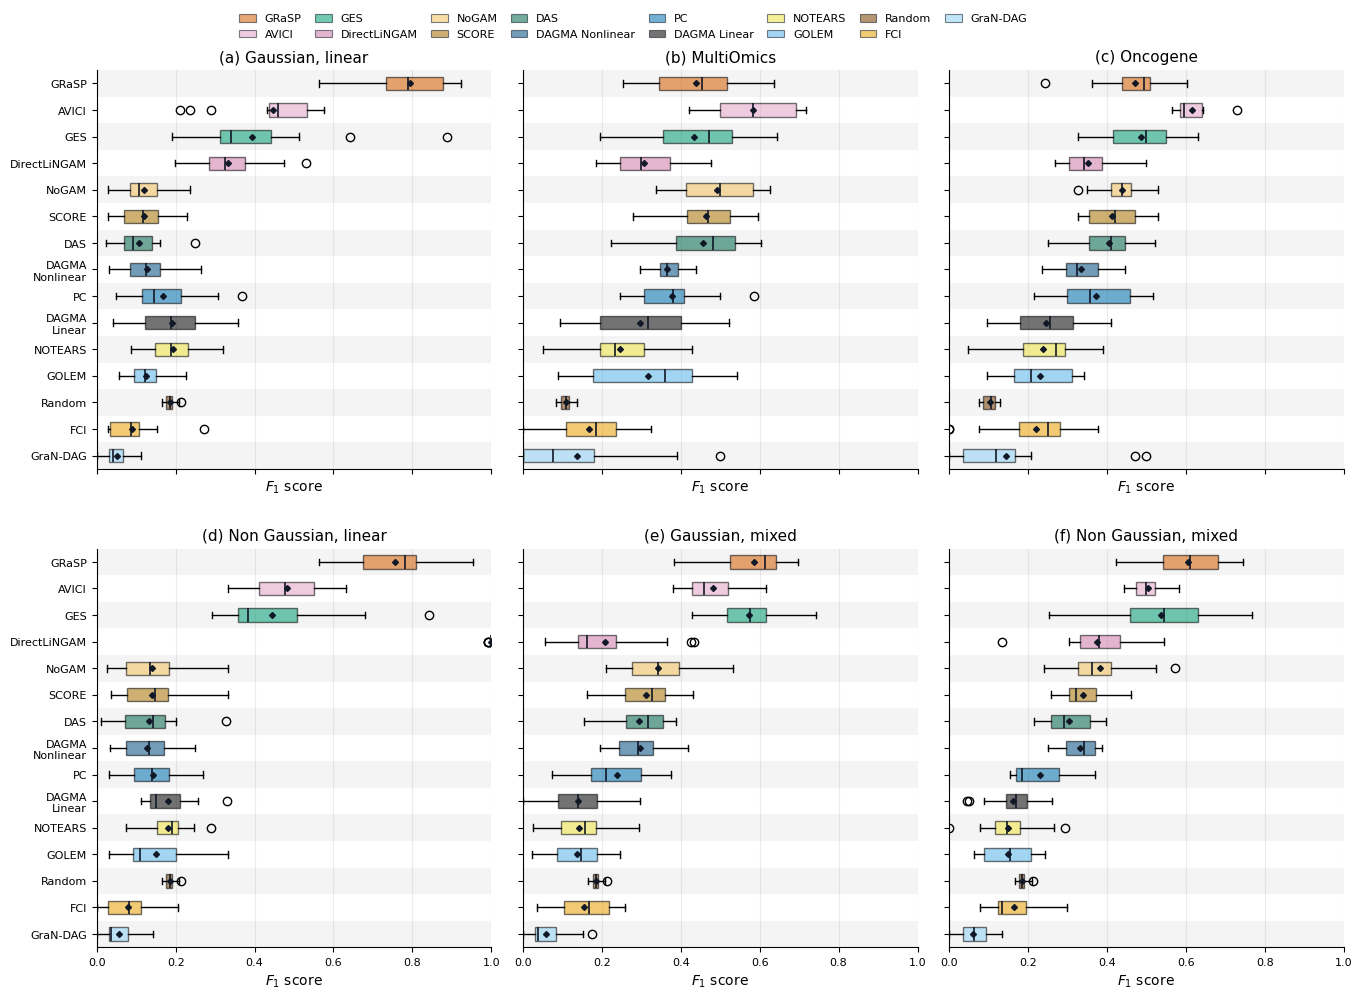

In [3]:
for panel_index, axis in enumerate(axes.ravel()):
    axis.tick_params(axis='y', labelleft=panel_index % 3 == 0)
display(fig)
plt.close(fig)
paper_panel_specs = [{'title': 'Gaussian, linear', 'datasets': '20nodes_EB_obsconf0_latconf0_Gaussian_Linear'}, {'title': 'Gaussian, linear, 6 observed confounders', 'datasets': '20nodes_EB_obsconf6_latconf0_Gaussian_Linear'}, {'title': 'Gaussian, linear, 6 latent confounders', 'datasets': '20nodes_EB_obsconf0_latconf6_Gaussian_Linear'}, {'title': 'Non Gaussian, linear', 'datasets': '20nodes_EB_obsconf0_latconf0_NonGaussian_Linear'}, {'title': 'Gaussian, mixed', 'datasets': '20nodes_EB_obsconf0_latconf0_Gaussian_Mixed'}, {'title': 'Non Gaussian, mixed', 'datasets': '20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed'}]
paper_order = ['GRaSP', 'AVICI', 'GES', 'DirectLiNGAM', 'NoGAM', 'SCORE', 'Random', 'DAGMA_Nonlinear', 'NOTEARS', 'DAS', 'DAGMA_Linear', 'PC', 'GOLEM', 'FCI', 'GraNDAG']


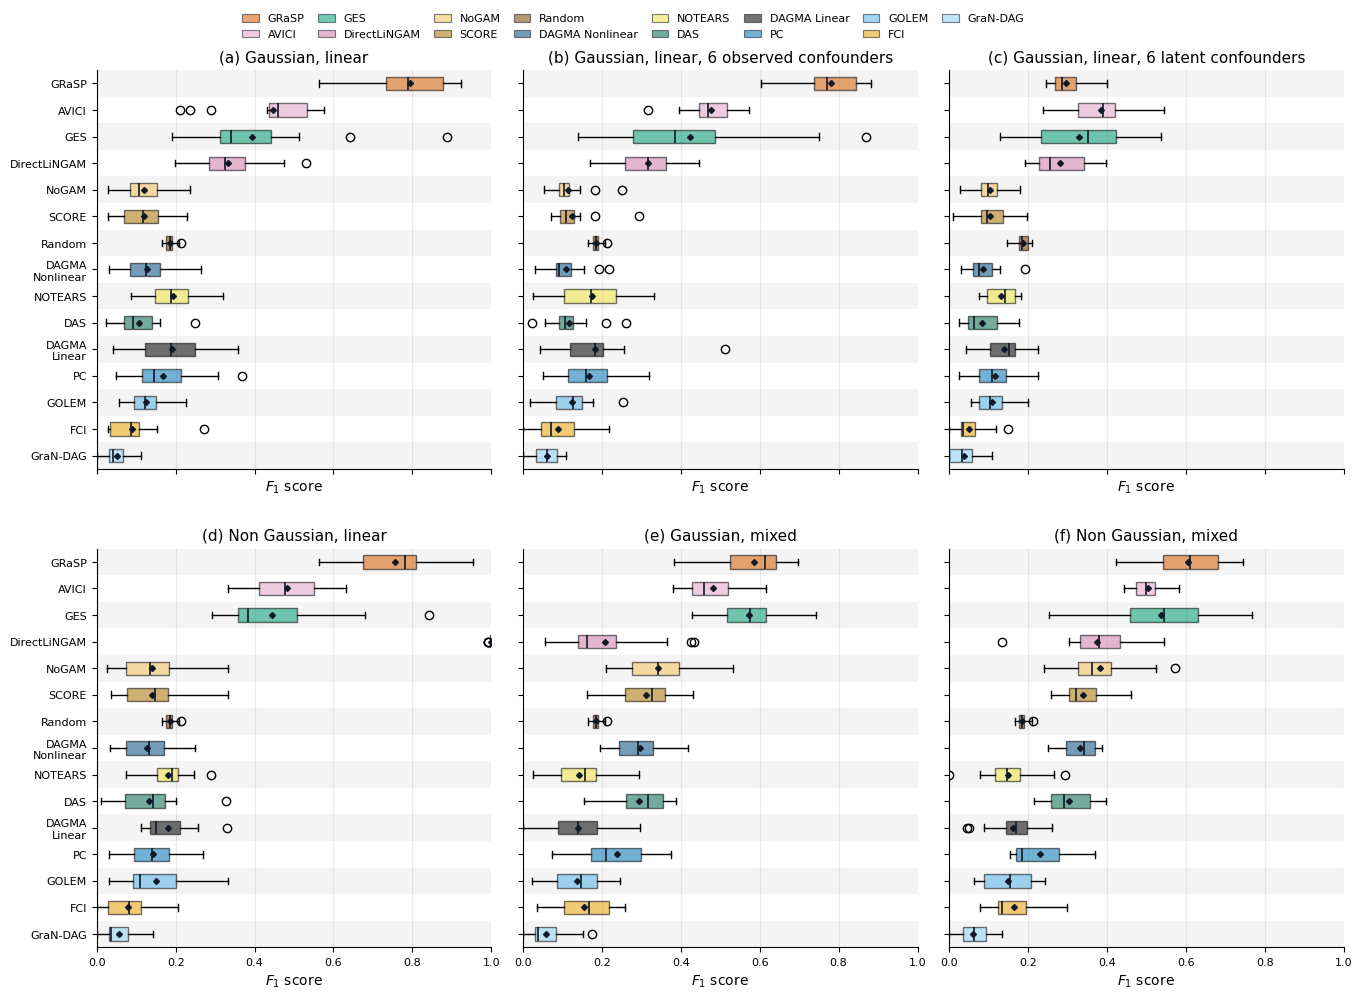

In [4]:
fig_paper_f1, axes_paper_f1, paper_f1_panel = fv.plot_metric_boxplot_grid(benchmark_data, paper_panel_specs, metric='f1', coverage_policy='all', plot_kind='box', show_fliers=True, whiskers='1.5iqr', order_by='manual', model_order=paper_order, marker_size=4.5, capsize=2.5, wrap_model_labels=True, show_model_bands=True, ylim=(0, 1), ncols=3, sharex=True, panel_labels=True, xlabel='$F_1$ score', legend_ncol=8, figsize=(14.5, 10.2), font_size=10, title_size=11)
for panel_index, axis in enumerate(axes_paper_f1.ravel()):
    axis.tick_params(axis='y', labelleft=panel_index % 3 == 0)
display(fig_paper_f1)
plt.close(fig_paper_f1)


### Performance, coverage and paired ranks


In [5]:
tables = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")
benchmark_rank_table = tables['benchmark_rank_table']
benchmark_f1 = tables['benchmark_f1']
benchmark_coverage = tables['benchmark_coverage']
display(benchmark_rank_table)


dataset,Method,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed,Median
0,GRaSP,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0
1,AVICI,2.0,3.0,1.0,3.0,2.0,1.0,1.0,2.0,1.0,1.0,1.5
2,GES,2.0,1.0,1.0,3.0,2.0,1.0,1.0,NaN,6.0,2.0,2.0
3,DirectLiNGAM,2.0,9.0,4.0,1.0,4.0,1.0,4.0,3.0,6.0,8.0,4.0
4,SCORE,9.0,4.0,4.0,5.0,4.0,7.0,10.0,4.0,1.0,2.0,4.0
5,DAS,9.0,4.0,4.0,5.0,8.0,7.0,10.0,4.0,1.0,2.0,4.5
6,NoGAM,9.0,4.0,4.0,5.0,4.0,7.0,10.0,11.0,1.0,2.0,4.5
7,PC,5.0,4.0,4.0,5.0,8.0,7.0,5.0,4.0,6.0,2.0,5.0
8,DAGMA Linear,5.0,9.0,10.0,5.0,10.0,5.0,5.0,4.0,6.0,8.0,5.5
9,DAGMA Nonlinear,9.0,4.0,4.0,5.0,4.0,7.0,10.0,11.0,6.0,8.0,6.5


## Coverage and runtime


In [6]:
sources = th.load_final_results()
main = sources["benchmark_with_biological"]
complete = sources["complete"]


### Completed and failed fits


In [7]:
tables = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")
runtime_tables = tables['runtime_tables']
coverage_tables = tables['coverage_tables']
for table in coverage_tables.values():
    display(table.head(20))


,dataset,model,recorded,completed,completion_fraction
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,15,15,1.0
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,15,15,1.0
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,225,225,1.0
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,15,15,1.0
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,15,15,1.0
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,225,225,1.0
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,15,15,1.0
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,15,15,1.0
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,225,225,1.0
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,15,15,1.0


,dataset,model,arm,recorded,completed,completion_fraction
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,tuned,15,15,1.0
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,untuned,15,15,1.0
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,tuned,15,15,1.0
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,untuned,15,15,1.0
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,tuned,75,75,1.0
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,untuned,75,75,1.0
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,tuned,15,15,1.0
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,untuned,15,15,1.0
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,tuned,15,15,1.0
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,untuned,15,15,1.0


In [8]:
for study in ("benchmark", "tuned_untuned"):
    print(study, "runtime among completed fits")
    display(runtime_tables[study])


benchmark runtime among completed fits
tuned_untuned runtime among completed fits


,dataset,model,mean,std,size
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,140.065600,3.189582,15
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,22.921800,3.959468,15
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,1507.767653,15.431060,15
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,149.613867,1.947192,15
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,13.193933,0.319515,15
...,...,...,...,...,...
145,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,NOTEARS,20.238133,6.030121,15
146,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,NoGAM,1494.558800,5.251188,15
147,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,PC,3.262467,1.299069,15
148,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,0.020236,0.001730,15


,dataset,model,arm,mean,std,size
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,tuned,56.576782,5.820481,15
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,untuned,109.341000,45.603141,15
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,tuned,34.515015,5.189321,15
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,untuned,21.969400,3.855693,15
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,tuned,1144.187066,2.711595,15
...,...,...,...,...,...,...
175,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,PC,untuned,2.872200,0.874147,15
176,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,PRISM,tuned,1140.317782,7.474766,15
177,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,untuned,0.023453,0.003523,15
178,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,SCORE,tuned,148.171200,1.388647,15


## All metrics by condition

Results for all 36 benchmark conditions at 10, 15, 20 and 30 variables. Metrics are summarised within dataset instances before averaging across instances.


In [9]:
import sys, json, textwrap
sys.path.insert(0, str(ROOT / 'analysis'))
frame = pd.concat([th.prepare_metrics(th.load_graph_size_results()), th.load_final_results()['benchmark_with_biological']], ignore_index=True)


In [10]:
def plot_conditions(table, metric, title, filename, bounded=False):
    models = sorted(table.model.unique(), key=th.model_label)
    sizes = sorted(table.n_nodes.unique())
    fig, axes = plt.subplots(2, 2, figsize=(19, 14), constrained_layout=True)
    maximum = 1.0 if bounded else float(table[metric].max())
    cmap = plt.colormaps['viridis'].copy()
    cmap.set_bad('#e8e8e8')
    for ax, size in zip(axes.flat, sizes):
        selected = table.loc[table.n_nodes.eq(size)]
        matrix = selected.pivot(index='dataset', columns='model', values=metric).reindex(columns=models)
        image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(float)), aspect='auto', cmap=cmap, vmin=0, vmax=maximum)
        labels = [textwrap.fill(name.split('nodes_', 1)[1].replace('_obsconf0_latconf0', '').replace('_', ' '), 33) for name in matrix.index]
        ax.set_yticks(range(len(matrix)), labels, fontsize=8)
        ax.set_xticks(range(len(models)), [th.model_label(m) for m in models], rotation=55, ha='right', fontsize=8)
        ax.set_title(f'{int(size)} variables')
    fig.colorbar(image, ax=axes.ravel().tolist(), label=title, shrink=0.7)
    display(fig)
    plt.close(fig)


In [11]:
tables = pd.read_pickle(ROOT / "results/analysis/benchmark.pkl")
coverage = tables['coverage']
summary = tables["metrics_summary"]
display(summary)


,dataset,n_nodes,model,f1_mean,f1_std,f1_count,fbeta_mean,fbeta_std,fbeta_count,precision_mean,precision_std,precision_count,recall_mean,recall_std,recall_count,SHD_mean,SHD_std,SHD_count,runtime_seconds_mean,runtime_seconds_std,runtime_seconds_count
0,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.616645,0.125270,15,0.604550,0.123588,15,0.602639,0.140202,15,0.662247,0.184608,15,9.333333,4.011887,15,134.321636,0.699079,15
1,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.268810,0.169676,15,0.269337,0.174773,15,0.270543,0.179083,15,0.270875,0.163921,15,13.933333,5.049281,15,12.667524,1.914128,15
2,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15,0.407303,0.094826,15,0.406923,0.096970,15,0.423129,0.104600,15,12.595556,4.375797,15,785.668178,11.219803,15
3,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.240082,0.131551,15,0.216088,0.124481,15,0.202792,0.120115,15,0.297379,0.145382,15,18.000000,5.606119,15,61.910240,0.534461,15
4,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.431603,0.148130,15,0.376885,0.139201,15,0.347943,0.133939,15,0.577306,0.171778,15,16.266667,7.245360,15,2.429996,0.098605,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.047282,0.031053,15,0.098956,0.060253,15,0.451905,0.256907,15,0.025367,0.017274,15,63.466667,4.470006,15,886.911840,5.699748,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.177434,0.053714,15,0.272399,0.066121,15,0.440746,0.099959,15,0.113447,0.040386,15,59.800000,5.226307,15,42.136267,27.409626,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.330373,0.109214,15,0.364162,0.121880,15,0.391503,0.132810,15,0.287199,0.094136,15,59.266667,6.963852,15,5.738907,1.306945,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.112131,0.006105,15,0.084869,0.005373,15,0.073039,0.004918,15,0.242441,0.008405,15,232.435556,2.082256,15,0.001849,0.000437,15


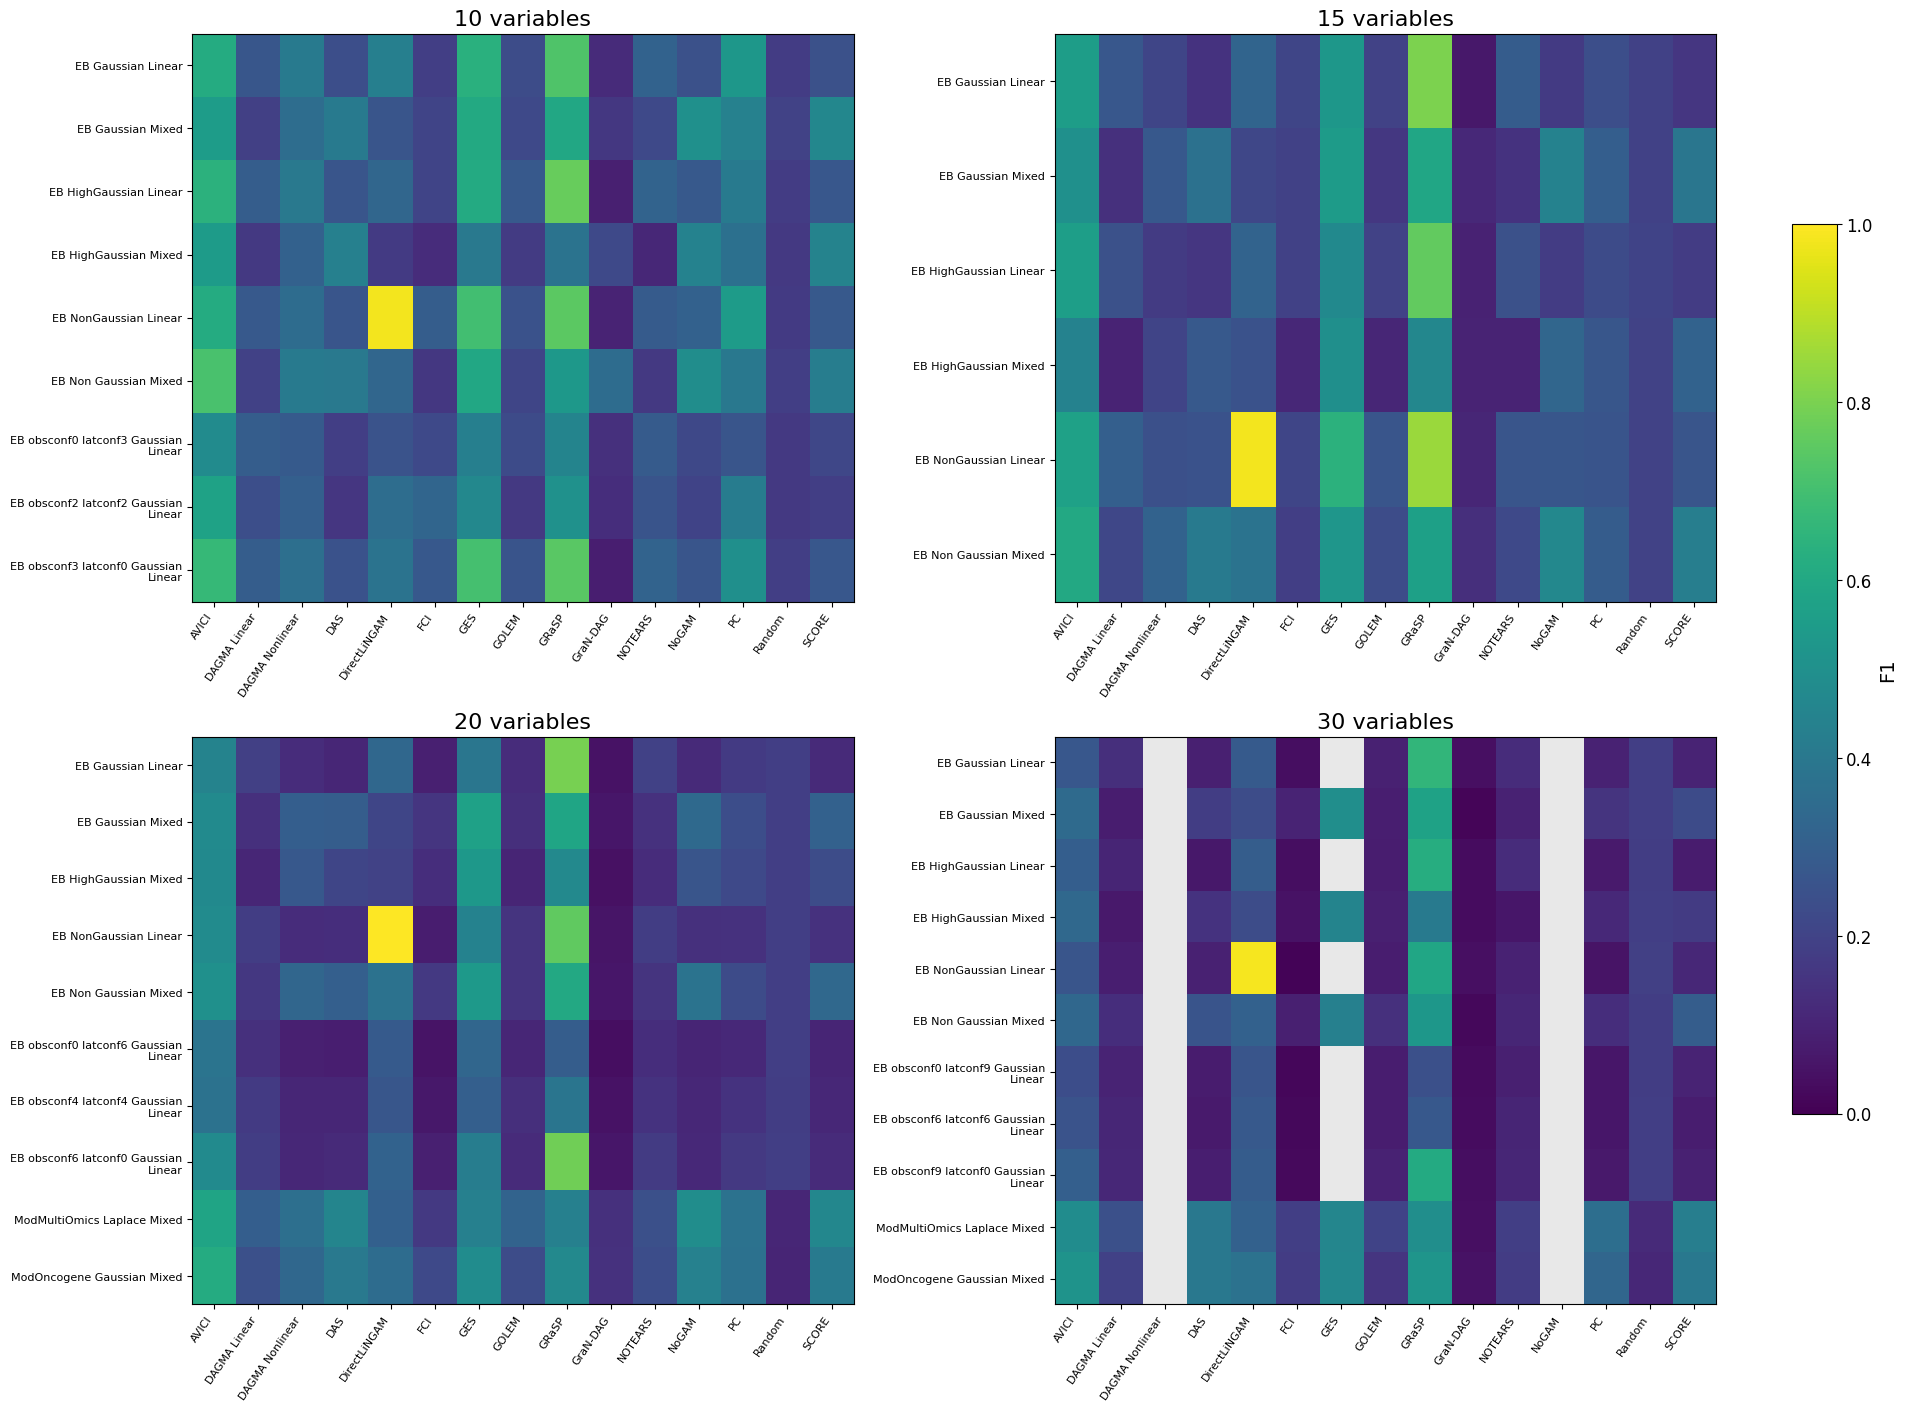

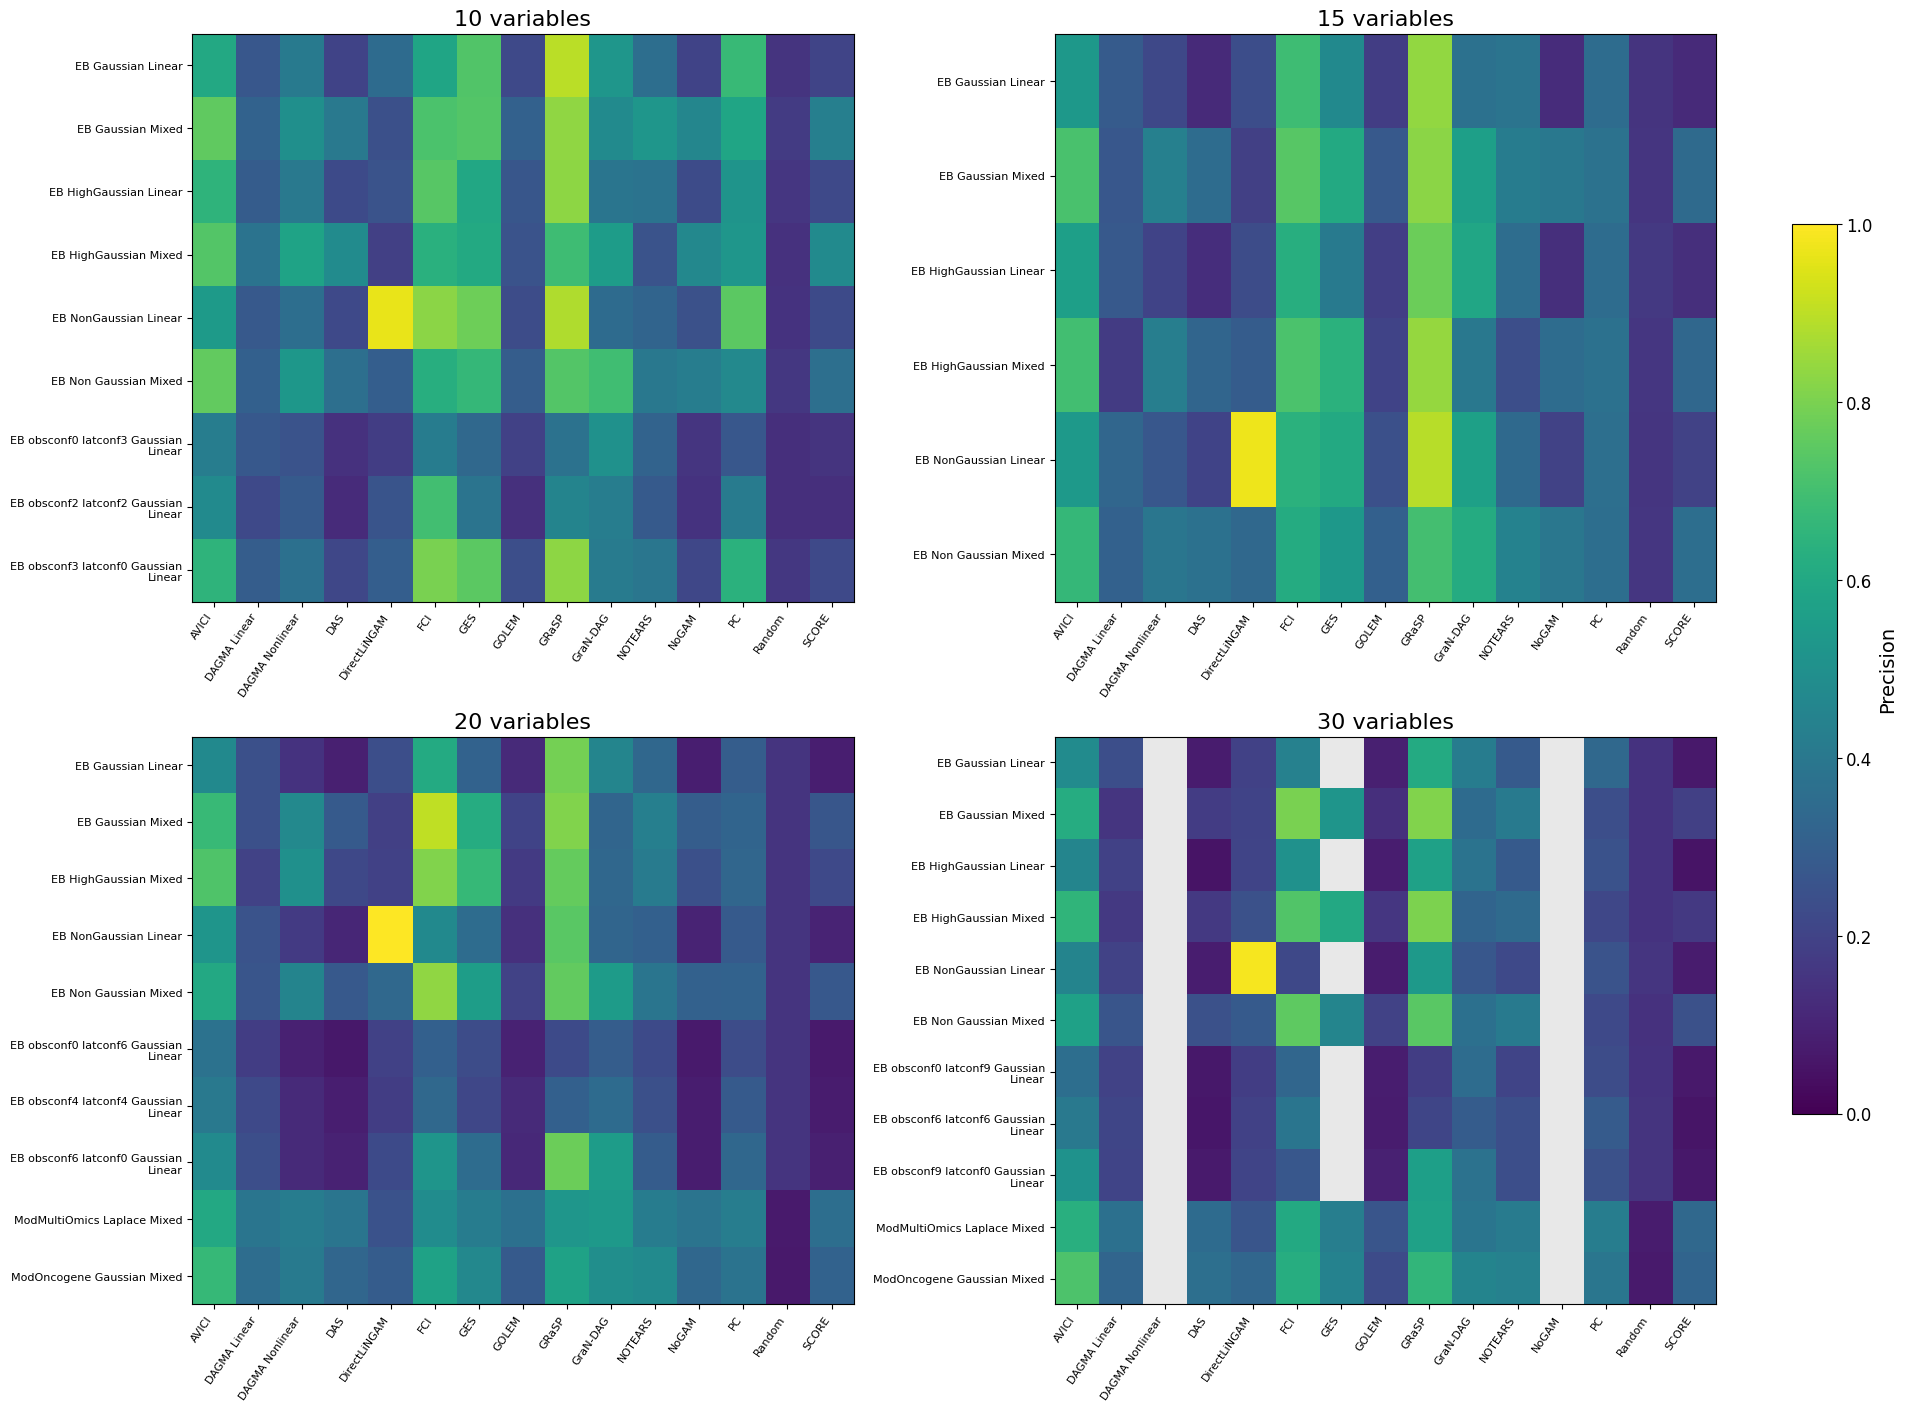

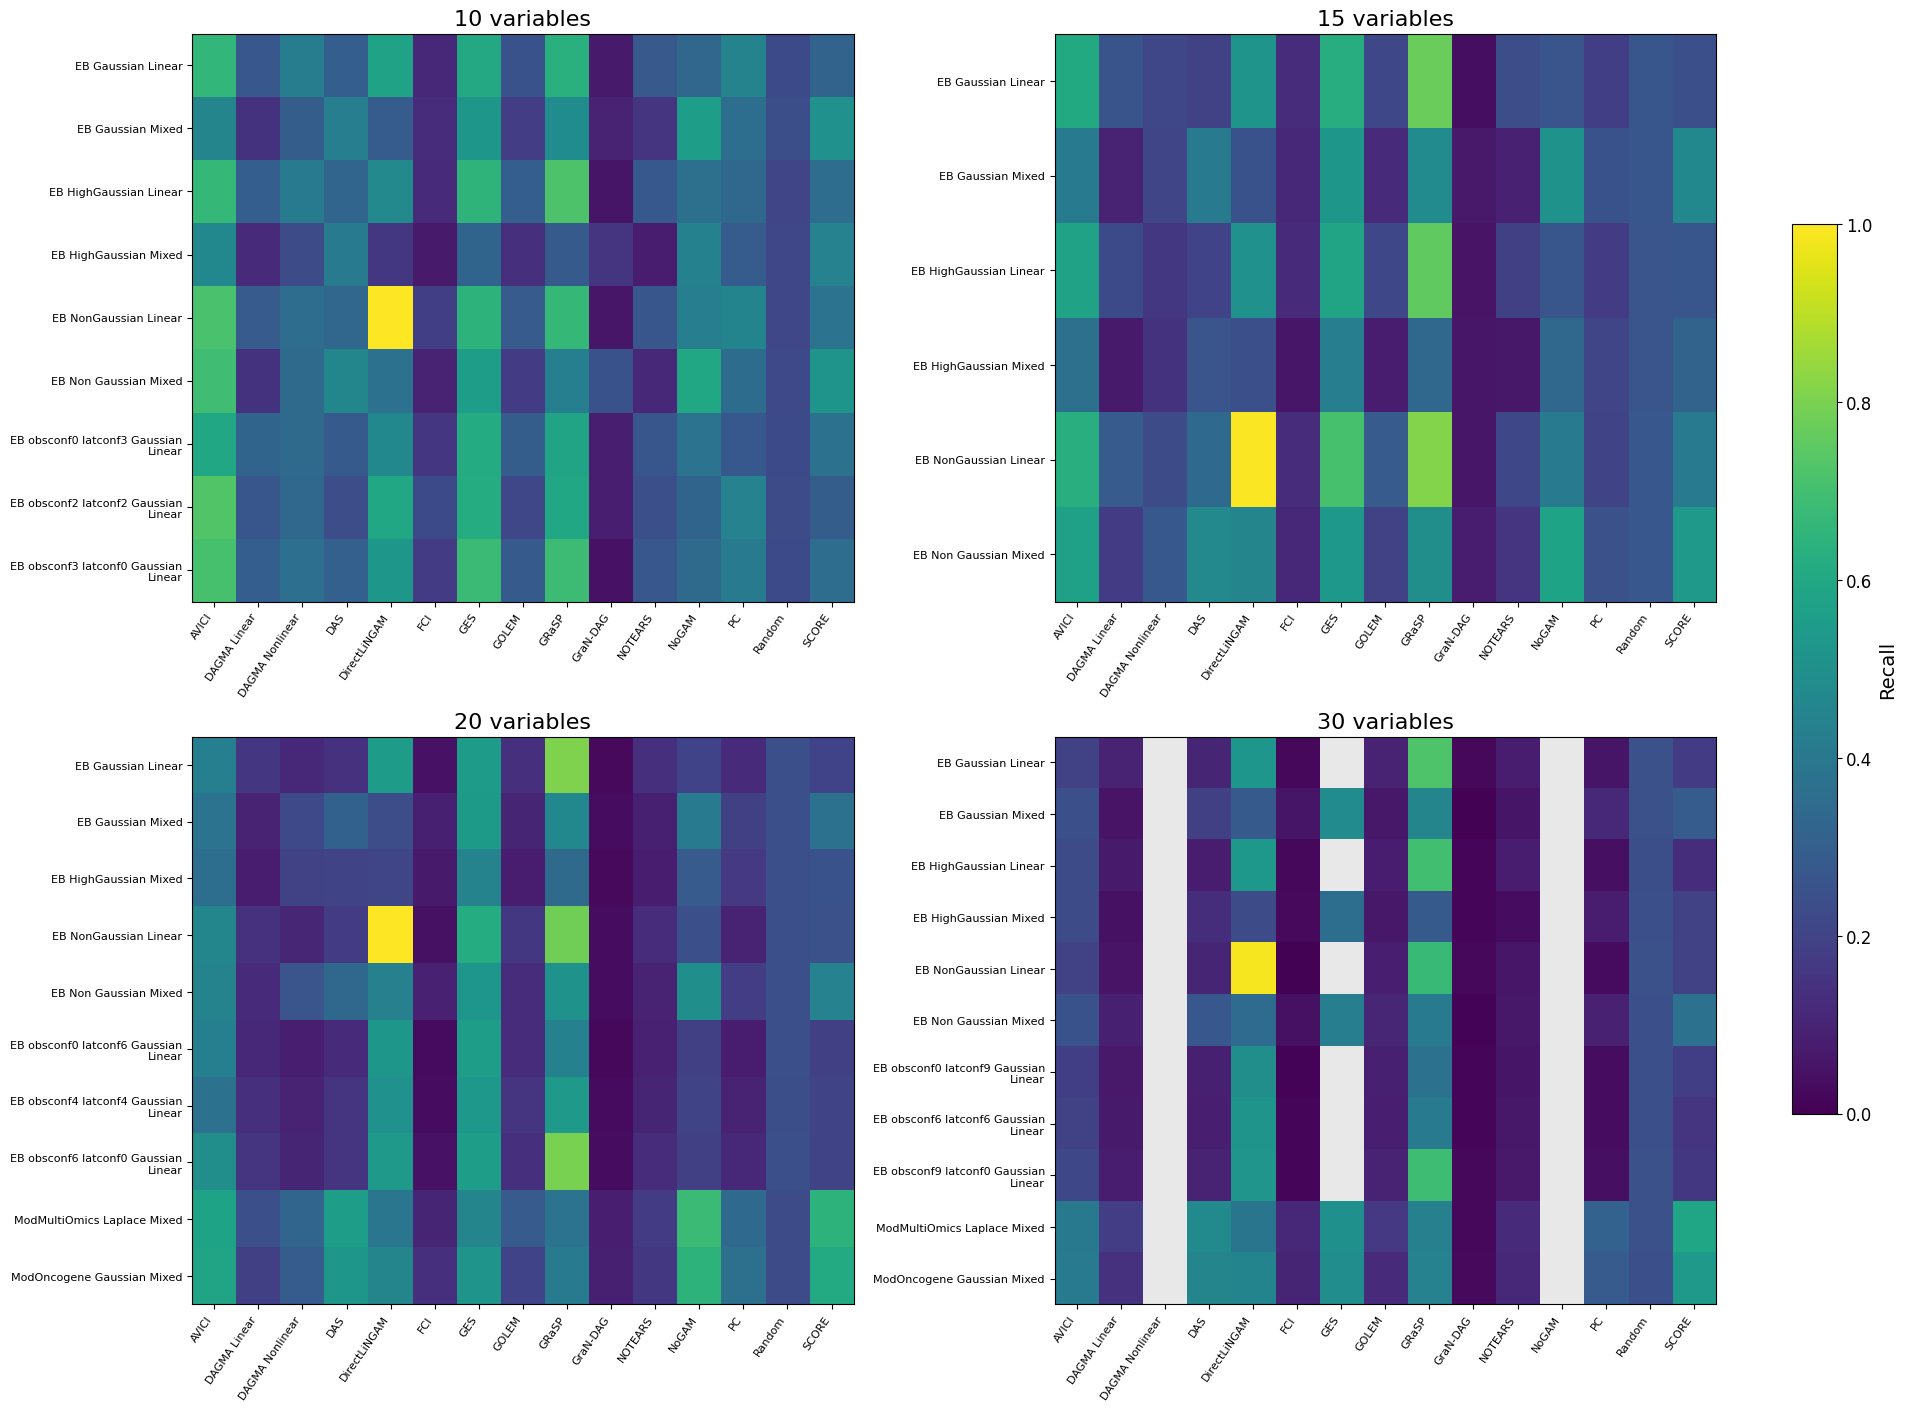

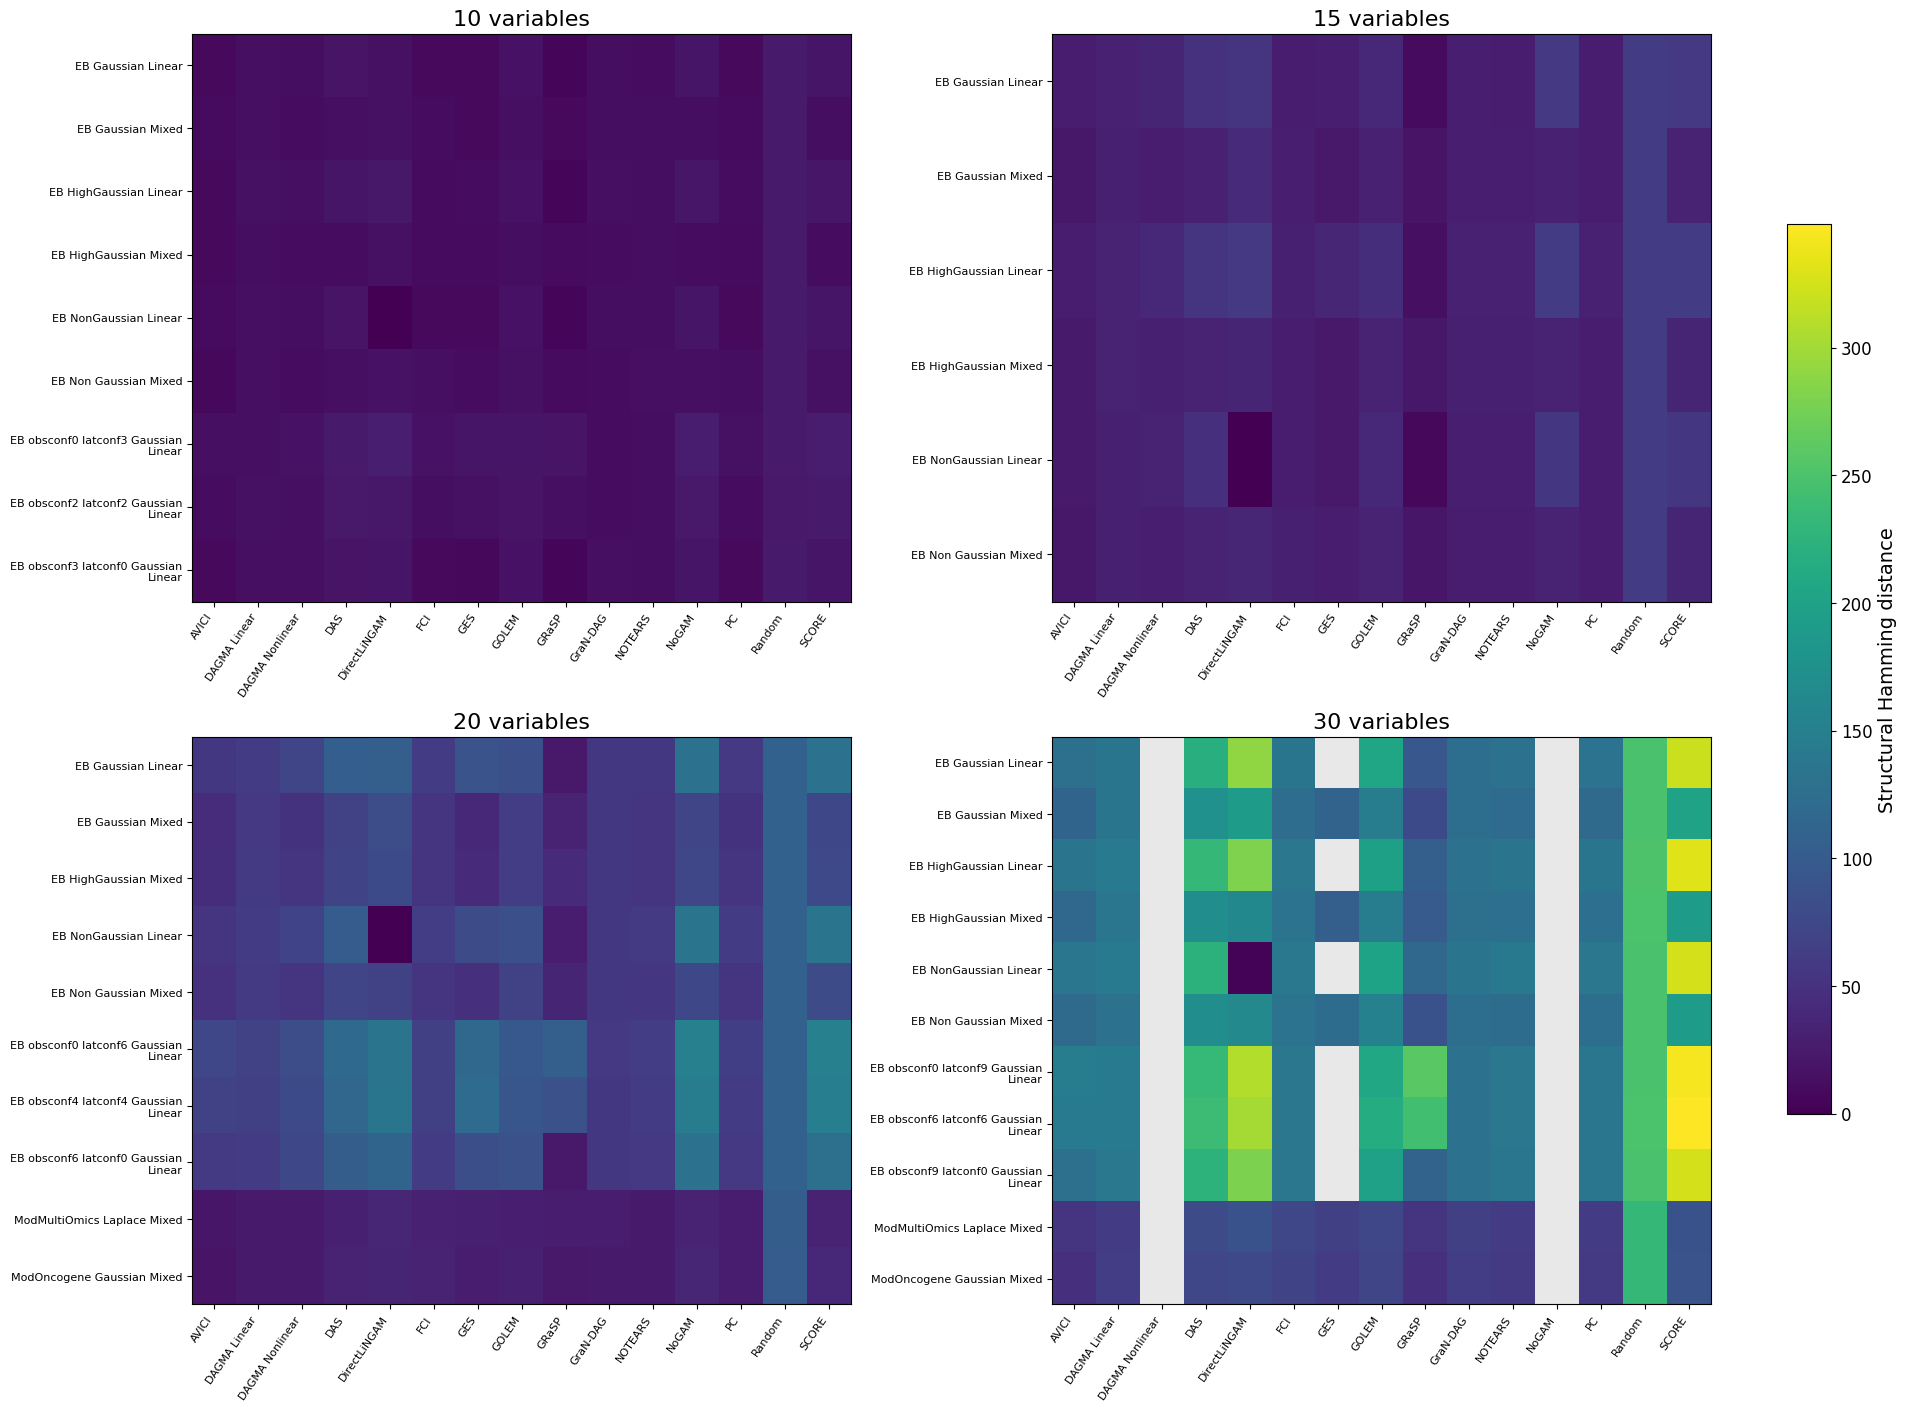

In [12]:
for metric, label in [("f1", "F1"), ("precision", "Precision"), ("recall", "Recall"), ("SHD", "Structural Hamming distance")]:
    plot_conditions(summary, f"{metric}_mean", label, f"{metric}_by_condition.pdf", bounded=metric != "SHD")
